V: 1.2
Cleaned from unneccessary functions

In [41]:
import torch
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.patches import Polygon
import cv2
import numpy as np
from ultralytics import YOLO
from ultralytics.utils.plotting import Annotator, colors
import re
import random # like my life lol

# ML libraries
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures

import pandas as pd

from sympy import sympify, symbols, solve

import matplotlib.image as mpimg

In [42]:
model_path = "/mnt/UE2ROS/Tomato/src/tomato/Jan.pt"
model = YOLO(model_path)

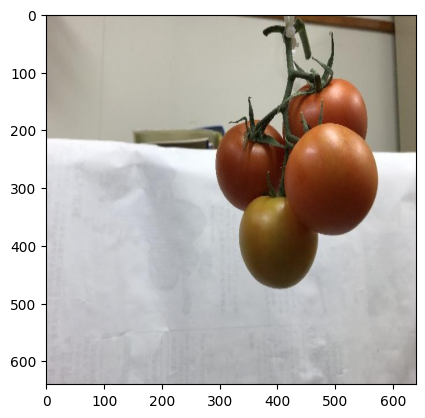

In [43]:
image_path1 = "/mnt/UE2ROS/Tomato/src/tomato/dataset_Jan/train/IMG_0375_jpg.rf.f02e5921b1b20677455ece136359f8b3.jpg"  # Update the path
image_path2 = "/mnt/UE2ROS/Tomato/src/tomato/dataset_Jan/train/16_JPG.rf.7341af50f7888fe4dbbbf85924db4274.jpg"  # Update the path
image_path3 = "/mnt/UE2ROS/Tomato/src/tomato/dataset_Jan/train/IMG_20191215_110844_jpg.rf.38f0ce664a18544a0ac25a427f2acbd3.jpg"
image_path4 = "/mnt/tomato2.jpg"
image_path5 = "/mnt/tomato1.jpg"

image1 = Image.open(image_path1)

# image1 = image1.rotate(180)

plt.imshow(image1)


0: 640x640 3 bad tomatos, 1 good tomato, 1 stem, 37.6ms
Speed: 3.6ms preprocess, 37.6ms inference, 4.8ms postprocess per image at shape (1, 3, 640, 640)


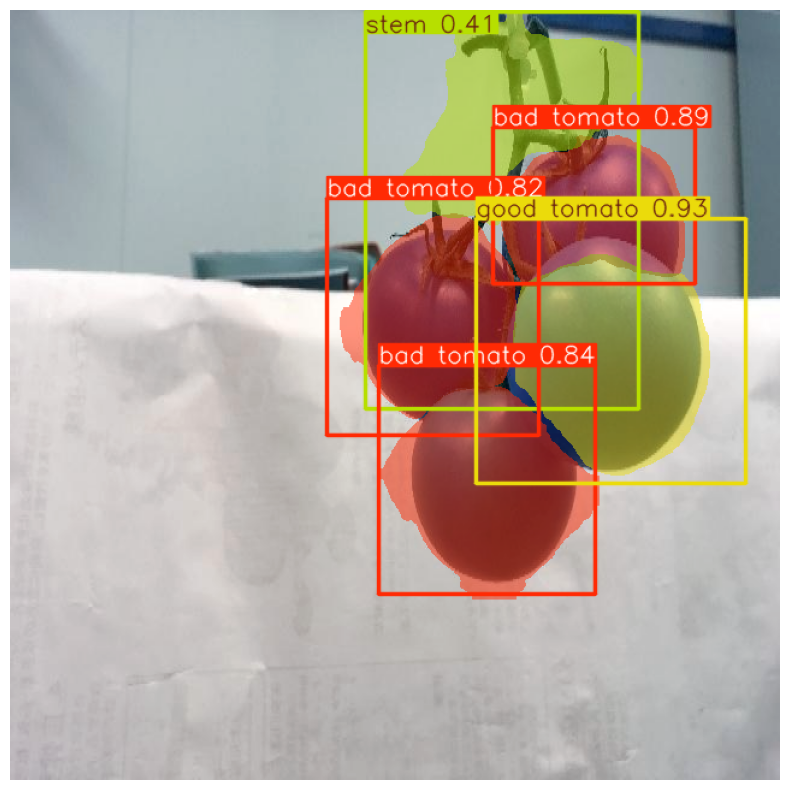

In [44]:
# labels = {0: 'bad tomato', 1: 'good tomato', 2: 'green tomato', 3: 'stem'}
results1 = model.predict(image1)

boxes = results1[0].boxes

annotated_image1 = results1[0].plot() 
plt.figure(figsize=(10, 10))
plt.imshow(annotated_image1)
plt.axis('off')
plt.show()

In [45]:
results1 = model.predict(image1)
boxes = results1[0].boxes

# Change into easily processable format
# return in format: {id : {label, confidence, img_box, contour}}
def get_tomatoes(img_prediction):
    tomatoes = {}
    numTomatoes = 0

    names = img_prediction[0].names
    contour_points = img_prediction[0].masks.xy
    labels = img_prediction[0].boxes.cls
    confidence = img_prediction[0].boxes.conf

    for idx, label in enumerate(labels):
        if label != 3:  # Assuming label 3 is not a tomato
            contourT = contour_points[idx].astype(int)

            # Get the real bounding box contour, correct the shape
            x_min = int(np.min(contourT[:, 0]))
            x_max = int(np.max(contourT[:, 0]))
            y_min = int(np.min(contourT[:, 1]))
            y_max = int(np.max(contourT[:, 1]))

            tomatoes[numTomatoes] = {
                'label': label,        # good, bad, green
                'confidence': confidence[idx].item(),
                'img_box': (x_min, x_max, y_min, y_max),
                'contour': contourT,
            }
            numTomatoes += 1
    return tomatoes


# @return: {region_id {box_coordinates, [points]}}
def get_regions_contours(one_tomato_dict, image):
    x_max, x_min, y_max, y_min = one_tomato_dict['img_box']  # e.g. 408 560 104 229

    grid_width = (x_max - x_min) // 3
    grid_height = (y_max - y_min) // 3

    all_regions = [
        (x_min + grid_width, x_min, y_min + grid_height, y_min),  # Top-left
        (x_min + 2 * grid_width, x_min + grid_width, y_min + grid_height, y_min),  # Top-center
        (x_max, x_min + 2 * grid_width, y_min + grid_height, y_min),  # Top-right
        (x_min + grid_width, x_min, y_min + 2 * grid_height, y_min + grid_height),  # Middle-left
        (x_min + 2 * grid_width, x_min + grid_width, y_min + 2 * grid_height, y_min + grid_height),  # Center
        (x_max, x_min + 2 * grid_width, y_min + 2 * grid_height, y_min + grid_height),  # Middle-right
        (x_min + grid_width, x_min, y_max, y_min + 2 * grid_height),  # Bottom-left
        (x_min + 2 * grid_width, x_min + grid_width, y_max, y_min + 2 * grid_height),  # Bottom-center
        (x_max, x_min + 2 * grid_width, y_max, y_min + 2 * grid_height),  # Bottom-right
    ]

    fig, ax = plt.subplots()
    ax.imshow(image)

    # Draw rectangles for each region
    for region in all_regions:
        rect = patches.Rectangle(
            (region[0], region[2]),  # x, y of the top-left corner
            region[1] - region[0],  # width
            region[3] - region[2],  # height
            linewidth=2,
            edgecolor='r',
            facecolor='none'
        )
        ax.add_patch(rect)
    
    # Assign the contour to each of its region
    contour = np.array(one_tomato_dict['contour'])
    regions_with_contours = {}
    for region_id, region in enumerate(all_regions):
        regions_with_contours[region_id] = {
            'region': region,  # Store the region box
            'points': []       # List to hold points in this region
        }

    for point in contour:
        x, y = point
        x = int(x)      # make them comparable (cos python has no static typing)
        y = int(y)
        for region_id, data in regions_with_contours.items():
            region = data['region']
            if region[0] <= x <= region[1] and region[2] <= y <= region[3]:
                regions_with_contours[region_id]['points'].append((x, y))
    return regions_with_contours

# debugging only
def plot_region_by_id(regions_with_contours, region_id, image):
    if region_id not in regions_with_contours:
        raise ValueError(f"Region {region_id} does not exist in the regions data.")

    region_data = regions_with_contours[region_id]
    region = region_data['region']
    points = region_data['points']

    # Plotting the specified region
    fig, ax = plt.subplots()
    ax.imshow(image)

    # Draw the rectangle for the specified region
    rect = patches.Rectangle(
        (region[0], region[2]),  # x, y of the top-left corner
        region[1] - region[0],  # width
        region[3] - region[2],  # height
        linewidth=2,
        edgecolor='r',
        facecolor='none'
    )
    ax.add_patch(rect)

    # Plot the points inside the specified region (optional)
    for point in points:
        ax.scatter(point[0], point[1], color='blue', s=1)  # Small blue dots for the points

    plt.title(f"Region {region_id} with {len(points)} points")
    plt.show()


0: 640x640 3 bad tomatos, 1 good tomato, 1 stem, 28.6ms
Speed: 3.1ms preprocess, 28.6ms inference, 4.7ms postprocess per image at shape (1, 3, 640, 640)


In [46]:
tomatoes = get_tomatoes(results1)
second_tomato = tomatoes[2]

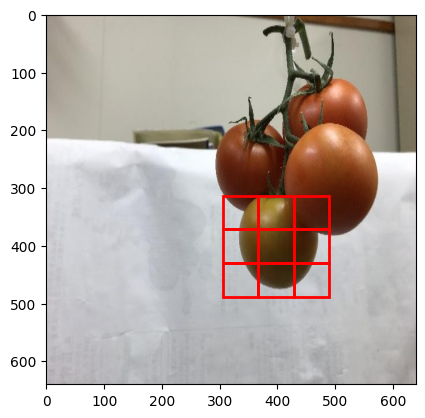

In [47]:
regions_with_contours = get_regions_contours(second_tomato, image1)

Functions for regrerssion: All regions


In [48]:
def linear_regression_on_all_regions(regions_with_contours):
    for region_id, region_data in regions_with_contours.items():
        region = region_data['region']
        points = region_data['points']

        # Handle no contour-points (common in the middle)
        if len(points) < 2:
            print(f"Warning: Not enough points in Region {region_id} to perform linear regression (requires at least 2 points).")
            continue

        X = np.array([point[0] for point in points]).reshape(-1, 1)  
        y = np.array([point[1] for point in points])  
        model = LinearRegression()
        model.fit(X, y)

        slope = model.coef_[0]
        intercept = model.intercept_
        equation = f"{slope:.2f}*x + {intercept:.2f}"

        polynomial_data = {
            'coefficients': float(slope), 
            'intercept': float(intercept)
        }

        regions_with_contours[region_id][f"linear"] = polynomial_data
    return regions_with_contours



def polynomial_regression_on_all_regions(regions_with_contours, polynomial_degree=2):
    for i in range(0, 9):
        region_data = regions_with_contours[i]
        region = region_data['region']
        points = region_data['points']
        lower_x = region[0]
        upper_x = region[1]
        lower_y = region[2]
        upper_y = region[3]

        # Handle no contour-points (common in the middle)
        if len(points) < 2:
            print(f"Warning: Not enough points in Region {i} to perform polynomial regression (requires at least 2 points).")
            continue

        # Prepare data for polynomial regression
        X = np.array([point[0] for point in points]).reshape(-1, 1)
        y = np.array([point[1] for point in points])

        # Initialize polynomial features of the specified degree
        poly = PolynomialFeatures(degree=polynomial_degree)
        X_poly = poly.fit_transform(X)

        # Initialize and fit the linear regression model on the transformed features
        model = LinearRegression()
        model.fit(X_poly, y)

        coefficients = model.coef_
        intercept = model.intercept_

        print(coefficients)
        

        # Generate the polynomial equation
        polynomial_data = {
            'coefficients': coefficients.tolist()[1:],  # Convert numpy array to list for easier storage
            'intercept': intercept
        }

        # Store the polynomial equation in the region data
        regions_with_contours[i][f"polynomial{polynomial_degree}"] = polynomial_data

    return regions_with_contours


In [49]:
# debugging only
def draw_regression(regions_with_contours, image, polynomial_order=2, show_image=True, show_contours=True, show_box=True):
    
    df_init = [[0, 0, 0],
                [0, 0, 0],
                [0, 0, 0]]
    df_columns = ['Column1', 'Column2', 'Column3']
    df_index = ['Row1', 'Row2', 'Row3']
    df = pd.DataFrame(df_init, columns=df_columns, index=df_index)

    fig_size = (10, 10) if show_image else (5, 5) 
    fig, ax = plt.subplots(figsize=fig_size)
    
    if show_image:
        ax.imshow(image) 

    for region_id, region_data in regions_with_contours.items():
        region = region_data['region']
        points = region_data['points']
        lower_x = region[0]
        upper_x = region[1]
        lower_y = region[2]
        upper_y = region[3]

        # Draw the bounding box for the region
        if show_box:
            rect = patches.Rectangle(
                (region[0], region[2]),  # x, y of the top-left corner
                region[1] - region[0],  # width
                region[3] - region[2],  # height
                linewidth=2,
                edgecolor='r',
                facecolor='none'
            )
            ax.add_patch(rect)

        if show_contours:
            ax.scatter([point[0] for point in points], [point[1] for point in points], color='blue', s=1)

        # Define variables
        x, y = symbols('x y')
        match polynomial_order:
            case 1:
                polys = region_data.get('linear')
                if polys is None:
                    print(f"No equation for region {region_id}")
                    continue
                else:
                    print(polys)
                    slope = float(polys['coefficients'][0]) if isinstance(polys['coefficients'], (list, np.ndarray)) else float(polys['coefficients'])
                    intercept = float(polys['intercept'])
                    fct = slope * x + intercept
            case 2:
                pol2 = region_data.get('polynomial2')
                if pol2 is None:
                    print(f"No polynomial2 equation for region {region_id}")
                    continue
                else:
                    c1 = float(pol2['coefficients'][0])
                    c0 = float(pol2['coefficients'][1])
                    intercept = float(pol2['intercept'])
                    fct = c0 * x**2 + c1 * x + intercept  
            case 3:
                pol3 = region_data.get('polynomial3')
                if pol3 is None:
                    print(f"No polynomial3 equation for region {region_id}")
                    continue
                else:
                    c2 = float(pol3['coefficients'][0])
                    c1 = float(pol3['coefficients'][1])
                    c0 = float(pol3['coefficients'][2])
                    intercept = float(pol3['intercept'])
                    fct = c0 * x**3 + c1 * x**2 + c2 * x + intercept

            case _:
                print("Insufficient polynomial degree")
                return

        if fct is None:
            continue

        # Generate x-values (a) and compute the corresponding y-values (result)
        a = np.linspace(lower_x, upper_x, 50)
        result = np.array([fct.subs(x, val) for val in a])
        result = np.array(result)
            
        # Filter the results based on the range y_min to y_max
        filtered_a = []
        filtered_result = []
        for i, val in enumerate(result):
            if lower_y <= val <= upper_y:
                filtered_a.append(a[i])
                filtered_result.append(val)

        # Plot the filtered results
        ax.plot(filtered_a, filtered_result, label=f"Region {region_id} Regression", linewidth=2, color="green")


    # Add legend and show the plot (after all regions are processed)
    ax.legend()
    plt.show()



In [50]:
regions_with_contours = linear_regression_on_all_regions(regions_with_contours)
polynomials_linear = polynomial_regression_on_all_regions(regions_with_contours, 2)
polynomials_linear = polynomial_regression_on_all_regions(regions_with_contours, 3)

for region_id, region_data in regions_with_contours.items():
    region = region_data['region']
    points = region_data['points']
    linear = region_data.get("linear", "No equation available")
    polynomial2 = region_data.get("polynomial2", "No equation available")
    polynomial3 = region_data.get("polynomial3", "No equation available")

regions_with_contours

[          0      1.1722  -0.0024997]
[          0      22.519   -0.028048]
[          0       22.09   -0.029601]
[          0      199.16    -0.20741]
[          0      30.903   -0.045331]
[          0    -0.90581    0.002533]
[          0     -8.5032    0.010877]
[          0     -4.0368   0.0044087]
[          0      185.08    -0.41183  0.00030351]
[          0     -28.406     0.10141 -0.00010951]
[          0      251.65     -0.6821  0.00061798]
[          0      1594.8     -3.1322   0.0020428]
[          0     -870.58      2.7509  -0.0028895]
[          0     -970.57      2.1844   -0.001636]
[          0      105.02    -0.27458  0.00023894]
[          0      -34.66    0.094038  -8.732e-05]


{0: {'region': (428, 489, 430, 489),
  'points': [(428, 478),
   (428, 476),
   (429, 472),
   (430, 472),
   (431, 471),
   (432, 471),
   (442, 461),
   (443, 461),
   (449, 455),
   (450, 455),
   (450, 454),
   (452, 452),
   (452, 450),
   (456, 446),
   (456, 445),
   (459, 442),
   (459, 441),
   (462, 438),
   (463, 438),
   (464, 437),
   (464, 436),
   (466, 434),
   (467, 434),
   (470, 431),
   (471, 431)],
  'linear': {'coefficients': -1.0678233438485805,
   'intercept': 932.7429022082019},
  'polynomial2': {'coefficients': [1.172195812308417, -0.002499670577860824],
   'intercept': np.float64(431.42051846218266)},
  'polynomial3': {'coefficients': [185.08313335909426,
    -0.4118274720601073,
    0.0003035050583832799],
   'intercept': np.float64(-27096.327279584704)}},
 1: {'region': (367, 428, 430, 489),
  'points': [(367, 465),
   (368, 465),
   (369, 466),
   (369, 467),
   (370, 468),
   (371, 468),
   (374, 471),
   (374, 473),
   (375, 474),
   (374, 475),
   (374,

In [51]:
# ONLY FULLY INITIALISED FOR POLYNOMIALS OF DEGREE2
def get_local_min_max(regions_with_contours, image, polynomial_order=2, show_image=True, show_contours=True, show_box=True):
    
    dict_l_max = {i: (np.nan, np.nan) for i in range(9)}
    dict_l_min = {i: (np.nan, np.nan) for i in range(9)}


    fig_size = (10, 10) if show_image else (5, 5) 
    fig, ax = plt.subplots(figsize=fig_size)
    
    if show_image:
        ax.imshow(image) 

    for region_id, region_data in regions_with_contours.items():
        region = region_data['region']
        points = region_data['points']
        lower_x = region[0]
        upper_x = region[1]
        lower_y = region[2]
        upper_y = region[3]

        # Draw the bounding box for the region
        if show_box:
            rect = patches.Rectangle(
                (region[0], region[2]),  # x, y of the top-left corner
                region[1] - region[0],  # width
                region[3] - region[2],  # height
                linewidth=2,
                edgecolor='r',
                facecolor='none'
            )
            ax.add_patch(rect)

        if show_contours:
            ax.scatter([point[0] for point in points], [point[1] for point in points], color='blue', s=1)

        # Define variables
        x, y = symbols('x y')
        match polynomial_order:
            case 1:
                print("Linear is not implemented.")
                return

            case 2: # only one fully initialised
                pol2 = region_data.get('polynomial2')
                if pol2 is None:
                    print(f"No polynomial2 equation for region {region_id}")
                    continue
                else:
                    c1 = float(pol2['coefficients'][0])
                    c0 = float(pol2['coefficients'][1])
                    intercept = float(pol2['intercept'])
                    fct = c0 * x**2 + c1 * x + intercept  
                    dydx = 2*c0 * x + c1 # first derivative
                    dy2dx2 = 2* c0 # second derivative

                    # find min_max for each area
                    critical_point = float(solve(dydx)[0]) # if this is more than one this is wrong
                    second_deriv = dy2dx2 # this is a constant lol
                    y = c0 * critical_point**2 + c1 * critical_point + intercept

                    # While this is less efficient, you will need to debug this, so do this step by step instead. first get all local ones
                    if(second_deriv < 0):   # this is mirrored !important (it is other way around)
                        dict_l_min[region_id] = critical_point, y
                        ax.scatter(critical_point, y, color='red', s=70, label=f"Min {region_id}")
                    else:
                        dict_l_max[region_id] = critical_point, y
                        ax.scatter(critical_point, y, color='yellow', s=70, label=f"Max {region_id}")

            case 3:
                print("Polynomial of degree 3 is not implemented.")
                return
            case _:
                print("Insufficient polynomial degree")
                return

        if fct is None:
            continue

        # Generate x-values (a) and compute the corresponding y-values (result)
        a = np.linspace(lower_x, upper_x, 50)
        result = np.array([fct.subs(x, val) for val in a])
        result = np.array(result)
            
        # Filter the results based on the range y_min to y_max
        filtered_a = []
        filtered_result = []
        for i, val in enumerate(result):
            if lower_y <= val <= upper_y:
                filtered_a.append(a[i])
                filtered_result.append(val)

        ax.plot(filtered_a, filtered_result, label=f"Region {region_id} Regression", linewidth=2, color="green")
    ax.legend()
    plt.show()
    
    return dict_l_min, dict_l_max

No polynomial2 equation for region 4


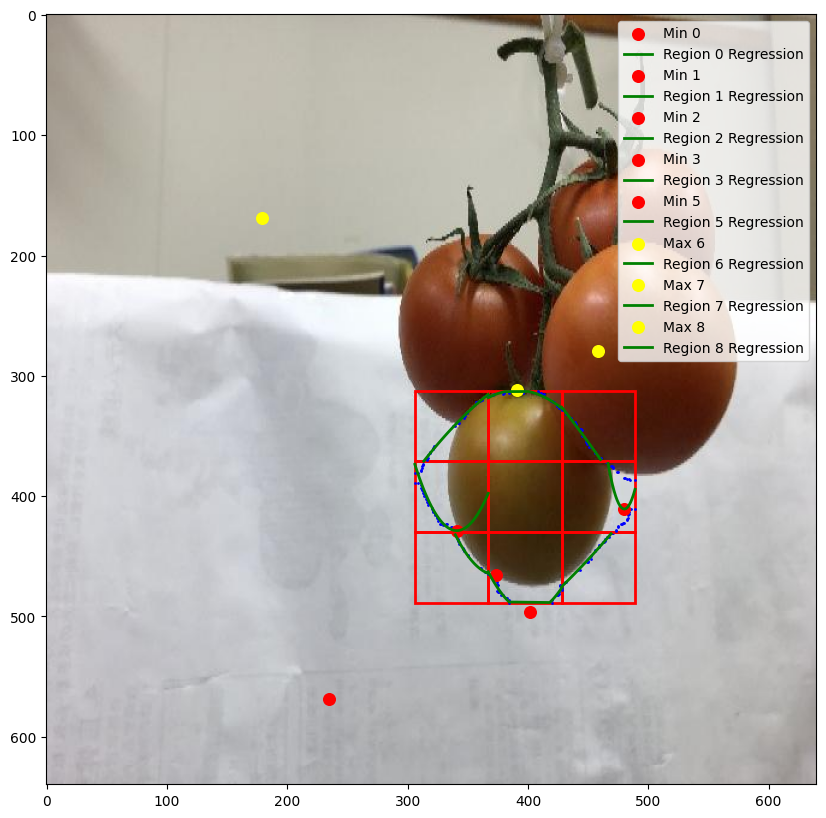

In [52]:
dict_l_min, dict_l_max = get_local_min_max(regions_with_contours, image1, 2)

In [53]:
print(dict_l_min)
pd.DataFrame.from_dict(dict_l_min, orient='index', columns=['x', 'y'])

{0: (234.47005831295678, 568.8429286952614), 1: (401.4450534090515, 496.14662342872225), 2: (373.12072748055556, 465.30478334411055), 3: (480.1040461233594, 410.73632833978627), 4: (nan, nan), 5: (340.85440644915013, 428.65655321540635), 6: (nan, nan), 7: (nan, nan), 8: (nan, nan)}


,x,y
0,234.470058,568.842929
1,401.445053,496.146623
2,373.120727,465.304783
3,480.104046,410.736328
4,NaN,NaN
5,340.854406,428.656553
6,NaN,NaN
7,NaN,NaN
8,NaN,NaN


In [54]:
print(dict_l_max)
pd.DataFrame.from_dict(dict_l_max, orient='index', columns=['x', 'y'])

{0: (nan, nan), 1: (nan, nan), 2: (nan, nan), 3: (nan, nan), 4: (nan, nan), 5: (nan, nan), 6: (178.80538202022822, 168.75827788415265), 7: (390.8822772206375, 312.00602693009296), 8: (457.8190450241818, 279.0363257034742)}


,x,y
0,NaN,NaN
1,NaN,NaN
2,NaN,NaN
3,NaN,NaN
4,NaN,NaN
5,NaN,NaN
6,178.805382,168.758278
7,390.882277,312.006027
8,457.819045,279.036326


In [55]:
def print_cleaned_regions_info(regions_with_contours):
    for region_id, region_data in regions_with_contours.items():
        region = region_data['region']
        points = region_data['points']
        lower_x = region[0]
        upper_x = region[1]
        lower_y = region[2]
        upper_y = region[3]
    
        # Print linear regression equation
        linear_reg = region_data.get('linear')
        if linear_reg:
            print(f"  Linear Regression Equation: {linear_reg}")
        
        # Print 2nd order polynomial regression equation
        pol2 = region_data.get('polynomial2')
        if pol2:
            print(f"  2nd order Polynomial Regression Equation: {pol2}")
        
        # Print 3rd order polynomial regression equation
        pol3 = region_data.get('polynomial3')
        if pol3:
            print(f"  3rd order Polynomial Regression Equation: {pol3}")
        
        # Print estimated points
        estimated_key = "30_estimated"
        if estimated_key in region_data:
            print(f"  Estimated points ({estimated_key}):")
            for point in region_data[estimated_key]:
                print(f"    Point: x = {point[0]}, y = {point[1]}")
        else:
            print(f"  No estimated points for {estimated_key}.\n")
    


In [56]:
regions_with_contours

{0: {'region': (428, 489, 430, 489),
  'points': [(428, 478),
   (428, 476),
   (429, 472),
   (430, 472),
   (431, 471),
   (432, 471),
   (442, 461),
   (443, 461),
   (449, 455),
   (450, 455),
   (450, 454),
   (452, 452),
   (452, 450),
   (456, 446),
   (456, 445),
   (459, 442),
   (459, 441),
   (462, 438),
   (463, 438),
   (464, 437),
   (464, 436),
   (466, 434),
   (467, 434),
   (470, 431),
   (471, 431)],
  'linear': {'coefficients': -1.0678233438485805,
   'intercept': 932.7429022082019},
  'polynomial2': {'coefficients': [1.172195812308417, -0.002499670577860824],
   'intercept': np.float64(431.42051846218266)},
  'polynomial3': {'coefficients': [185.08313335909426,
    -0.4118274720601073,
    0.0003035050583832799],
   'intercept': np.float64(-27096.327279584704)}},
 1: {'region': (367, 428, 430, 489),
  'points': [(367, 465),
   (368, 465),
   (369, 466),
   (369, 467),
   (370, 468),
   (371, 468),
   (374, 471),
   (374, 473),
   (375, 474),
   (374, 475),
   (374,

# To-Do: 
<li>make function of circle estimation for 0, 2, 6 and 8
<li>make function for mirroring

In [57]:
# only 2nd degree polynomial is implemented
# clean first row, last row then sides, returns n points for each region that is kept for ellipsis fitting
def generate_estimated_points(fct, lower_x, upper_x, lower_y, upper_y, n_points, max_attempts=10000):
    points = []
    attempts = 0

    while len(points) < n_points and attempts < max_attempts:
        attempts += 1
        x = random.uniform(lower_x, upper_x)
        y = fct(x)

        if not np.isnan(y) and lower_y <= y <= upper_y:
            points.append((x, y))

    if len(points) < n_points:
        print(f"Warning: Only generated {len(points)} points out of {n_points} after {attempts} attempts.")

    return points


def get_function(region_data, region_id, degree=2):
    pol2 = region_data.get('polynomial2')
    print(pol2)
    if pol2 is None:
        print(f"No polynomial2 equation for region {region_id}")
        return np.nan
    else:
        c1 = float(pol2['coefficients'][0])
        c0 = float(pol2['coefficients'][1])
        intercept = float(pol2['intercept'])
        fct = lambda x: c0 * x**2 + c1 * x + intercept
        return fct

"""
def get_function(region_data, degree=2):
    print("DEBUG: Full region_data:", region_data)  # Print full input
    print("DEBUG: Keys in region_data:", region_data.keys())  # Print available keys
    
    pol2 = region_data.get('polynomial2')
    print("DEBUG: pol2 value:", pol2)  # Print what we got from .get()
    
    if pol2 is None:
        print("No polynomial2 equation")
        return np.nan
    else:
        c1 = float(pol2['coefficients'][0])
        c0 = float(pol2['coefficients'][1])
        intercept = float(pol2['intercept'])
        fct = lambda x: c0 * x**2 + c1 * x + intercept
        print(f"DEBUG: Created function with coefficients {c0}, {c1} and intercept {intercept}")
        return fct
"""

# u should resample the number of points that were originally found within that area too to give greater weight to it, but lets keep it simple for now
def clean_of_occlusion(regions_with_contours, image_1, dict_l_min, dict_l_max, n_points=30, occluded_points=50, polynomial_order=2):
    for region_id, region_data in regions_with_contours.items():
        print(f"\nProcessing region_id: {region_id}")  # Add this
        region = region_data['region']
        points = region_data['points']
        lower_x = region[0]
        upper_x = region[1]
        lower_y = region[2]
        upper_y = region[3]

        x, y = symbols('x y')
        try:
            fct = get_function(region_data, region_id)
            if not callable(fct):  # Ensure fct is a function
                raise TypeError(f"Expected a callable function, got {type(fct)} with value {fct}")
            print(f"function: {fct}")
        except TypeError as e:
            print(f"-- No function of degree {polynomial_order} fallback --")
            fct = lambda x: np.nan  # Ensure fct is always callable

        match region_id:
            # <--- clean first row region 6-8
            # ideally: global max in 7, local max of 6 and 8 out of bounds -> simplified: only max
            case 8:
                if np.isnan(dict_l_max[8][0]): # there can only be a max or a min for 2nd degree polynomial
                    m_x = upper_x
                    m_y = upper_y
                    r = upper_y - lower_y

                    theta = np.linspace(3/2 * np.pi, 1 * np.pi, 30)  # Divide the quarter circle into 30 points
                    x_points = m_x + r * np.cos(theta)  # x-coordinates
                    y_points = m_y + r * np.sin(theta)  # y-coordinates

                    quarter_circle_points = list(zip(x_points, y_points))

                    regions_with_contours[region_id][f"{n_points}_estimated"] = quarter_circle_points

                else:
                    max_x, max_y = dict_l_max[8]
                    if max_x < upper_x:
                        upper_x = max_x
                     # coordinate system origin is topper left hand corner
                    n_estimated = generate_estimated_points(fct, lower_x, upper_x, lower_y, upper_y, n_points)
                    print(n_estimated)
                    regions_with_contours[region_id][f"{n_points}_estimated"] = n_estimated
            case 7:
                if np.isnan(dict_l_max[7][0]):  # occluded
                    mirrored_points = []
                    # get 50 estimated function values (oversample)
                    n_estimated = generate_estimated_points(fct, lower_x, upper_x, lower_y, upper_y, occluded_points)
                    for x, y in n_estimated:
                        mirrored_y = 2*lower_y - y  # Mirror the y-coordinate
                        mirrored_points.append((x, mirrored_y))
                    regions_with_contours[region_id][f"{n_points}_estimated"] = mirrored_points



                else:
                    n_estimated = generate_estimated_points(fct, lower_x, upper_x, lower_y, upper_y, n_points)
                    regions_with_contours[region_id][f"{n_points}_estimated"] = n_estimated
            case 6:
                if np.isnan(dict_l_max[6][0]):
                    # estimate circle
                    n_estimated = generate_estimated_points(fct, lower_x, upper_x, lower_y, upper_y, occluded_points)
                   
                    m_x = lower_x # midpoint of circle lower left hand corner
                    m_y = upper_y
                    r = upper_y - lower_y

                    theta = np.linspace(2 * np.pi, 3/2 * np.pi, 30)  # Divide the quarter circle into 30 points
                    x_points = m_x + r * np.cos(theta)  # x-coordinates
                    y_points = m_y + r * np.sin(theta)  # y-coordinates

                    quarter_circle_points = list(zip(x_points, y_points))

                    regions_with_contours[region_id][f"{n_points}_estimated"] = quarter_circle_points

                    
                    print("region 6 was estimated")
                
                else:
                    min_x, min_y = dict_l_max[6]    # only get the right arm
                    if min_x > lower_x:
                        lower_x = min_x
                    n_estimated = generate_estimated_points(fct, lower_x, upper_x, lower_y, upper_y, n_points)
                    regions_with_contours[region_id][f"{n_points}_estimated"] = n_estimated
            # clean first row region 6-8 --->
            # <---  clean last row region 0-2 , ideally only min
            case 2:
                # this couuld be so much easier but yk legacy hits different
                if np.isnan(dict_l_min[2][0]):
                    n_estimated = generate_estimated_points(fct, lower_x, upper_x, lower_y, upper_y, occluded_points)
                    # get function of bisecting
                    # bisecting_m = (upper_x - lower_x)/(upper_y - lower_y) # this axis system is mirrored, so we need to mirror on perpendicular of actual bisecting
                    # x1, y1 = upper_x, upper_y
                    # bisecting_c = y1 - bisecting_m * x1
                    # bisecting_line = lambda x: bisecting_m * x + bisecting_c
                    m_x = upper_x
                    m_y = lower_y
                    r = upper_y - lower_y

                    theta = np.linspace(np.pi, 1/2 * np.pi, 30)  # Divide the quarter circle into 30 points
                    x_points = m_x + r * np.cos(theta)  # x-coordinates
                    y_points = m_y + r * np.sin(theta)  # y-coordinates

                    quarter_circle_points = list(zip(x_points, y_points))

                    regions_with_contours[region_id][f"{n_points}_estimated"] = quarter_circle_points

                else:
                    min_x, min_y = dict_l_min[2]
                    if min_x < upper_x:
                        upper_x = min_x
                        upper_y = min_y
                    n_estimated = generate_estimated_points(fct, lower_x, upper_x, lower_y, upper_y, n_points)
                    regions_with_contours[region_id][f"{n_points}_estimated"] = n_estimated            
            case 1:
                if np.isnan(dict_l_min[1][0]): # occluded, mirror coordinate of max by y-constant at lowest point of bounding box
                    mirrored_points = []
                    # get 50 estimated function values (oversample)
                    n_estimated = generate_estimated_points(fct, lower_x, upper_x, lower_y, upper_y, occluded_points)
                    for x, y in n_estimated:
                        mirrored_y = 2*upper_y - y  # Mirror the y-coordinate
                        mirrored_points.append((x, mirrored_y))
                    regions_with_contours[region_id][f"{n_points}_estimated"] = mirrored_points
                else:
                    n_estimated = generate_estimated_points(fct, lower_x, upper_x, lower_y, upper_y, n_points)
                    regions_with_contours[region_id][f"{n_points}_estimated"] = n_estimated 

            case 0:
                if np.isnan(dict_l_min[0][0]):
                    m_x = lower_x
                    m_y = lower_y
                    r = upper_y - lower_y
                    theta = np.linspace(2*np.pi, 3/2 * np.pi, 30)  # Divide the quarter circle into 30 points
                    x_points = m_x + r * np.cos(theta)  # x-coordinates
                    y_points = m_y + r * np.sin(theta)  # y-coordinates
                    quarter_circle_points = list(zip(x_points, y_points))
                    regions_with_contours[region_id][f"{n_points}_estimated"] = quarter_circle_points

                else:
                    min_x, min_y = dict_l_min[0]
                    if min_x > lower_x:
                        lower_x = min_x
                        upper_y = min_y
                    n_estimated = generate_estimated_points(fct, lower_x, upper_x, lower_y, upper_y, n_points)
                    regions_with_contours[region_id][f"{n_points}_estimated"] = n_estimated            
            # clean last row region 0-2  --->

            # >>>>>>>>>>>>>>>>>>>> ONLY NON-OCCLUDED ESTIMATE ATM >>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>
            # >>>>>>>>>>>>>>>>>>>> THIS PART NEEDS REVISION UNDER OCCLUSION (if estimate is e.g. occluded and falsified parabola drawn) >>>>>>>>>>>>>>>>
            # <--- clean middle parts  
            # middle part can either have min|max and still be sufficient
            case 5:
                # check whether this has a function at all
                if np.isnan(dict_l_min[5][0]) and np.isnan(dict_l_max[5][0]):
                    continue


                if np.isnan(dict_l_min[5][0]):  # opens downwards, get left arm only
                    max_x, max_y = dict_l_max[5]
                    upper_x = max_x
                else:
                    min_x, min_y = dict_l_min[5] 
                    if min_x < lower_x:         # minimum is further left than bounding box, so get right arm
                        lower_x = lower_x       # this case occurs if segmentation was rlly bad
                    else:                       # opens upwards, get left arm only
                        upper_x = min_x
                n_estimated = generate_estimated_points(fct, lower_x, upper_x, lower_y, upper_y, n_points)
                regions_with_contours[region_id][f"{n_points}_estimated"] = n_estimated            
            
            case 3:
                if np.isnan(dict_l_min[3][0]) and np.isnan(dict_l_max[3][0]):
                    continue

                if np.isnan(dict_l_max[3][0]):  # opens downwards, get right arm only
                    min_x, min_y = dict_l_min[3]
                    lower_x = min_x
                else:
                    max_x, max_y = dict_l_max[3]   # open upwards, get right arm only
                    if upper_x > max_x:
                        lower_x = max_x

                n_estimated = generate_estimated_points(fct, lower_x, upper_x, lower_y, upper_y, n_points)
                regions_with_contours[region_id][f"{n_points}_estimated"] = n_estimated            
            # clean middle parts --->

    return regions_with_contours


In [58]:
estimated_values = clean_of_occlusion(regions_with_contours, image1, dict_l_min, dict_l_max)


Processing region_id: 0
{'coefficients': [1.172195812308417, -0.002499670577860824], 'intercept': np.float64(431.42051846218266)}
function: <function get_function.<locals>.<lambda> at 0x7fc84f731f30>

Processing region_id: 1
{'coefficients': [22.519359635904404, -0.028047872859151113], 'intercept': np.float64(-4023.9961424579183)}
function: <function get_function.<locals>.<lambda> at 0x7fc84f732d40>

Processing region_id: 2
{'coefficients': [22.089843820455858, -0.029601469703404604], 'intercept': np.float64(-3655.7845147660546)}
function: <function get_function.<locals>.<lambda> at 0x7fc84f731f30>

Processing region_id: 3
{'coefficients': [199.15731714267375, -0.20741057980117716], 'intercept': np.float64(-47397.38055929549)}
function: <function get_function.<locals>.<lambda> at 0x7fc84f732d40>

Processing region_id: 4
None
No polynomial2 equation for region 4
-- No function of degree 2 fallback --

Processing region_id: 5
{'coefficients': [30.90272886356225, -0.04533127382082469], '

In [59]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def plot_estimated_points_on_image(image, regions_with_estimated_points, regions_with_contours):
    # Create a figure and axis
    fig_size = (10, 10)
    fig, ax = plt.subplots(figsize=fig_size)

    # Display the image
    ax.imshow(image)

    # Plot bounding boxes
    for region_id, region_data in regions_with_contours.items():
        region = region_data['region']
        lower_x = region[0]
        upper_x = region[1]
        lower_y = region[2]
        upper_y = region[3]

        # Draw the bounding box for the region
        rect = patches.Rectangle(
            (lower_x, lower_y),  # x, y of the top-left corner
            upper_x - lower_x,   # width
            upper_y - lower_y,   # height
            linewidth=2,
            edgecolor='r',
            facecolor='none'
        )
        ax.add_patch(rect)

    # Plot estimated points
    for region_id, region_data in regions_with_estimated_points.items():
        if '30_estimated' in region_data:
            estimated_points = region_data['30_estimated']
            for point in estimated_points:
                x, y = point
                # Plot each point as a blue dot
                ax.scatter(x, y, color='blue', s=10)  # 's' controls the size of the dots

    # Set labels
    ax.set_xlabel("x")
    ax.set_ylabel("y")

    # Display the plot
    plt.show()

# Example call (replace 'image1', 'estimated_values', and 'regions_with_contours' with your data)
# plot_estimated_points_on_image(image1, estimated_values, regions_with_contours)


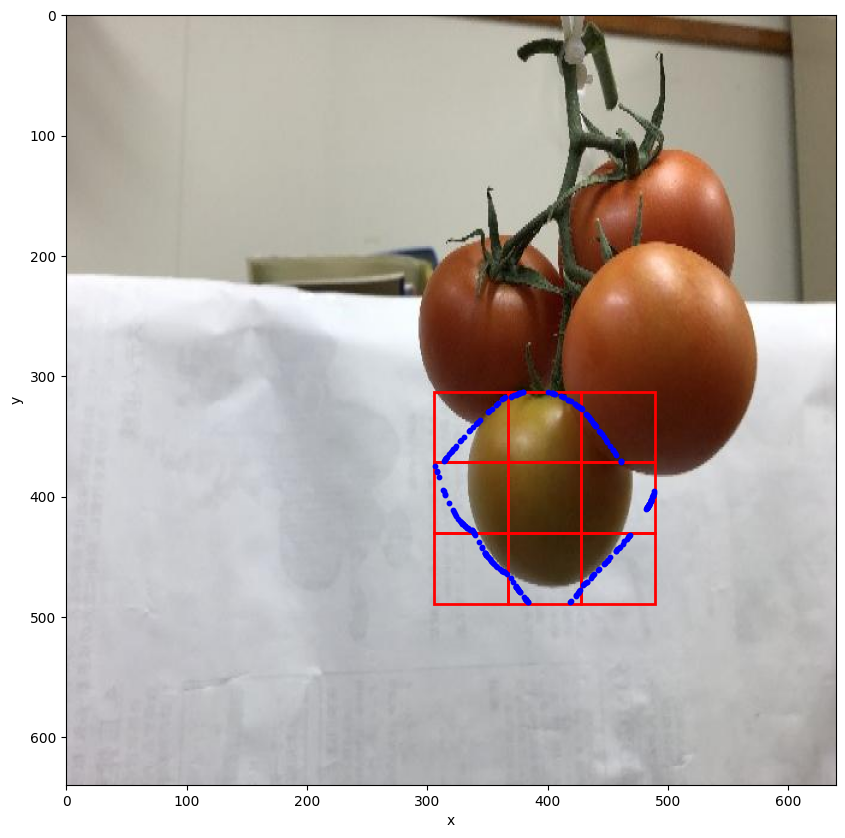

In [60]:
plot_estimated_points_on_image(image1, estimated_values, regions_with_contours)

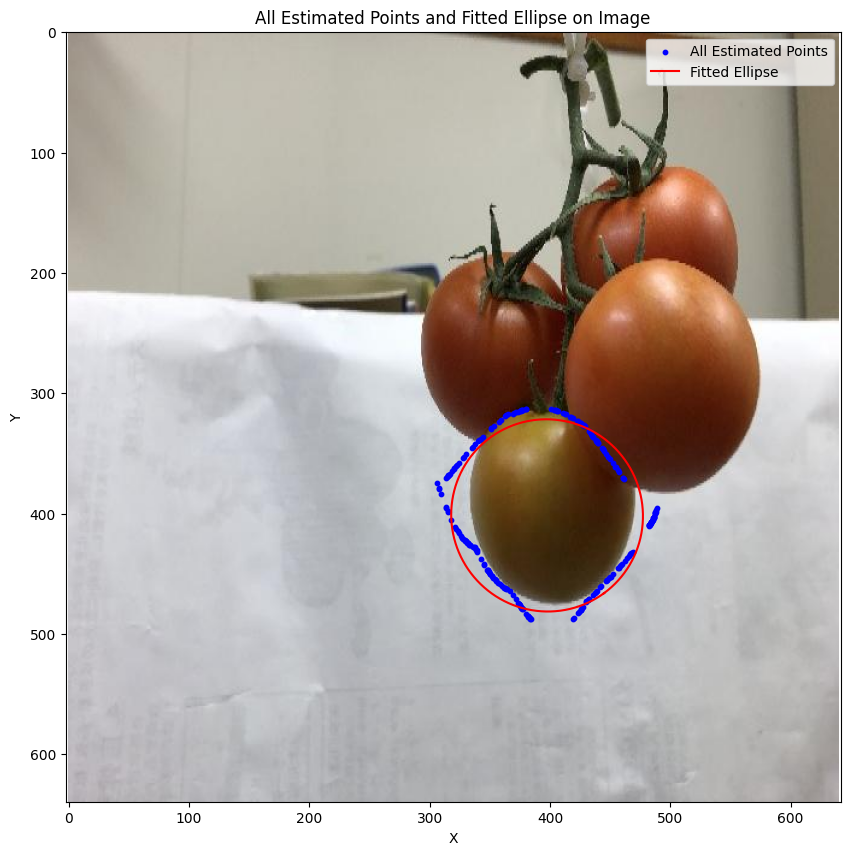

In [61]:
import numpy as np
import matplotlib.pyplot as plt

def plot_estimated_points_and_ellipse_on_image(image, regions_with_estimated_points):
    """
    Plots all estimated points from all regions and fits a single ellipse over them on the given image.

    Args:
        image (ndarray): The input image to plot on.
        regions_with_estimated_points (dict): A dictionary containing region IDs and their estimated points.
    """
    # Make a copy of the image to avoid modifying the original image
    image_copy = image.copy()

    plt.figure(figsize=(10, 10))
    plt.imshow(image_copy)

    all_points = []

    # Collect all points from all regions
    for region_id, region_data in regions_with_estimated_points.items():
        if '30_estimated' in region_data:
            all_points.extend(region_data['30_estimated'])

    # Convert all points to a NumPy array
    all_points = np.array(all_points)
    x, y = all_points[:, 0], all_points[:, 1]

    # Plot all estimated points
    plt.scatter(x, y, color='blue', s=10, label="All Estimated Points")

    # Fit an ellipse to all points
    x_mean, y_mean = x.mean(), y.mean()
    x -= x_mean
    y -= y_mean
    U, S, V = np.linalg.svd(np.stack((x, y)))

    # Generate ellipse points
    t = np.linspace(0, 2 * np.pi, 1000)
    circle = np.stack((np.cos(t), np.sin(t)))
    transform = np.sqrt(2 / len(all_points)) * U.dot(np.diag(S))
    fit = transform.dot(circle) + np.array([[x_mean], [y_mean]])

    # Plot the fitted ellipse
    plt.plot(fit[0, :], fit[1, :], 'r', label="Fitted Ellipse")

    # Configure plot
    plt.axis('equal')
    plt.legend()
    plt.title("All Estimated Points and Fitted Ellipse on Image")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.show()

# Example usage
plot_estimated_points_and_ellipse_on_image(image1, estimated_values)
